<a href="https://colab.research.google.com/github/a2w3r4/PINNs/blob/main/PINNS_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import the relevant libraries

In [1]:
import torch
import torch.nn as nn
from time import perf_counter
from PIL import Image
import matplotlib.pyplot as plt
from functools import partial
import numpy as np
import requests
import os

# check if GPU is aavialable and use it else use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

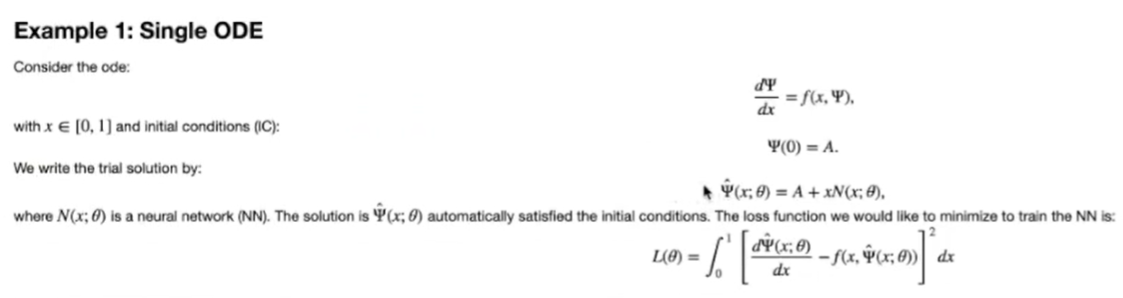

In [2]:
# N is a Neural Network -- This is exactly the network used by Lagaris rt al. 1997
N = nn.Sequential(nn.Linear(1, 50), nn.Sigmoid(), nn.Linear(50,1, bias=False))

# Initial condition
A = 0.

# The Psi_t function
Psi_t = lambda x: A + x * N(x)

# The right hand side function
f = lambda x, Psi: torch.exp(-x / 5.0) * torch.cos(x) - Psi / 5.0

# The loss function
def loss(x):
  x.requires_grad = True
  outputs = Psi_t(x)
  Psi_t_x = torch.autograd.grad(outputs, x, torch.ones_like(outputs), create_graph=True)[0]

  return torch.mean((Psi_t_x - f(x, outputs))  **  2)

First, we'll use the method that we find in Lagaris.rt.al instead of using stochastic optimization, they use a lot of points to estimate the loss integral ( we will use 100) and then they just do gradient - based optimization ( We will do BFGS)

<>:31: SyntaxWarning: invalid escape sequence '\P'
<>:31: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_1648/596508699.py:31: SyntaxWarning: invalid escape sequence '\P'
  ax.set_ylabel('$\Psi(x)$')


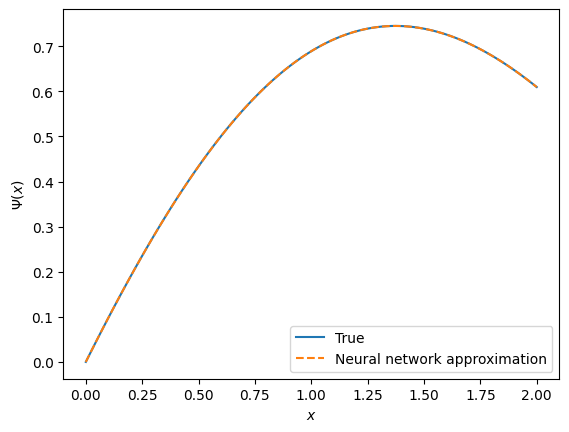

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Optimize (name algorithm as in Lagaris)
optimizer = torch.optim.LBFGS(N.parameters())

# The collection points used by Lagaris
x = torch.Tensor(np.linspace(0, 2, 100)[:, None])

# Run the optimizer
def closure():
  optimizer.zero_grad()
  l = loss(x)
  l.backward()
  return l

for i in range(10):
    optimizer.step(closure)

# Let's compare the result to the true solution
xx = np.linspace(0, 2, 100)[:, None]
with torch.no_grad():
    yy = Psi_t(torch.Tensor(xx)).numpy()
yt = np.exp(-xx / 5.0) * np.sin(xx)

fig, ax = plt.subplots(dpi=100)
ax.plot(xx, yt, label='True')
ax.plot(xx, yy, '--', label='Neural network approximation')
ax.set_xlabel('$x$')
ax.set_ylabel('$\Psi(x)$')
plt.legend(loc='best')
plt.show()

Now, let's use stochastic gradient descent to minimize the loss integrals

In [4]:
# We need to reinitialize the network
N = nn.Sequential(nn.Linear(1, 50), nn.Sigmoid(), nn.Linear(50,1, bias=False))

# Let's see now if a stochastic optimizer makes a difference
adam = torch.optim.Adam(N.parameters(), lr=0.01)

# The batch size you want to use (how many points to use per iteration)
n_batch = 5

# The maximum no. of iteraction to do
max_it = 1000

for i in range(max_it):
  #Randomly pick n_batch random x's:
  x = torch.rand(n_batch, 1)
  #zero-out the gradient buffers
  adam.zero_grad()
  #Evaluate the lose
  l = loss(x)
  #Calculate the gradients
  l.backward()
  #Update the networks
  adam.step()
  # Print the iteration number
  if i % 100 == 0:
    print(i)

0
100
200
300
400
500
600
700
800
900


<>:11: SyntaxWarning: invalid escape sequence '\P'
<>:11: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_1648/2421644429.py:11: SyntaxWarning: invalid escape sequence '\P'
  ax.set_ylabel('$\Psi(x)$')


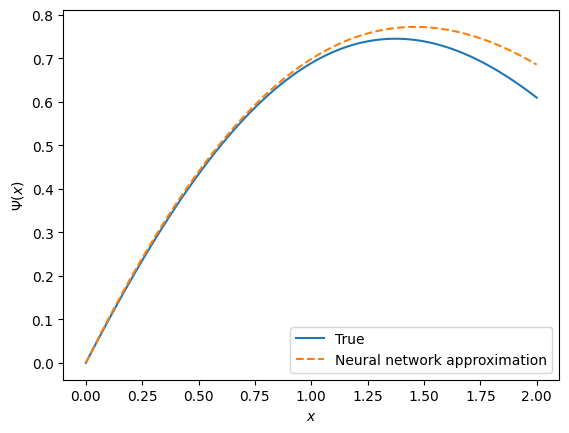

In [5]:
# Let's compare the result to the true solution
xx = np.linspace(0, 2, 100)[:, None]
with torch.no_grad():
    yy = Psi_t(torch.Tensor(xx)).numpy()
yt = np.exp(-xx / 5.0) * np.sin(xx)

fig, ax = plt.subplots(dpi=100)
ax.plot(xx, yt, label='True')
ax.plot(xx, yy, '--', label='Neural network approximation')
ax.set_xlabel('$x$')
ax.set_ylabel('$\Psi(x)$')
plt.legend(loc='best')
plt.show()

The main of this example to show How we set-up the loss function and Parameterize the loss-function using the differential eq^n.

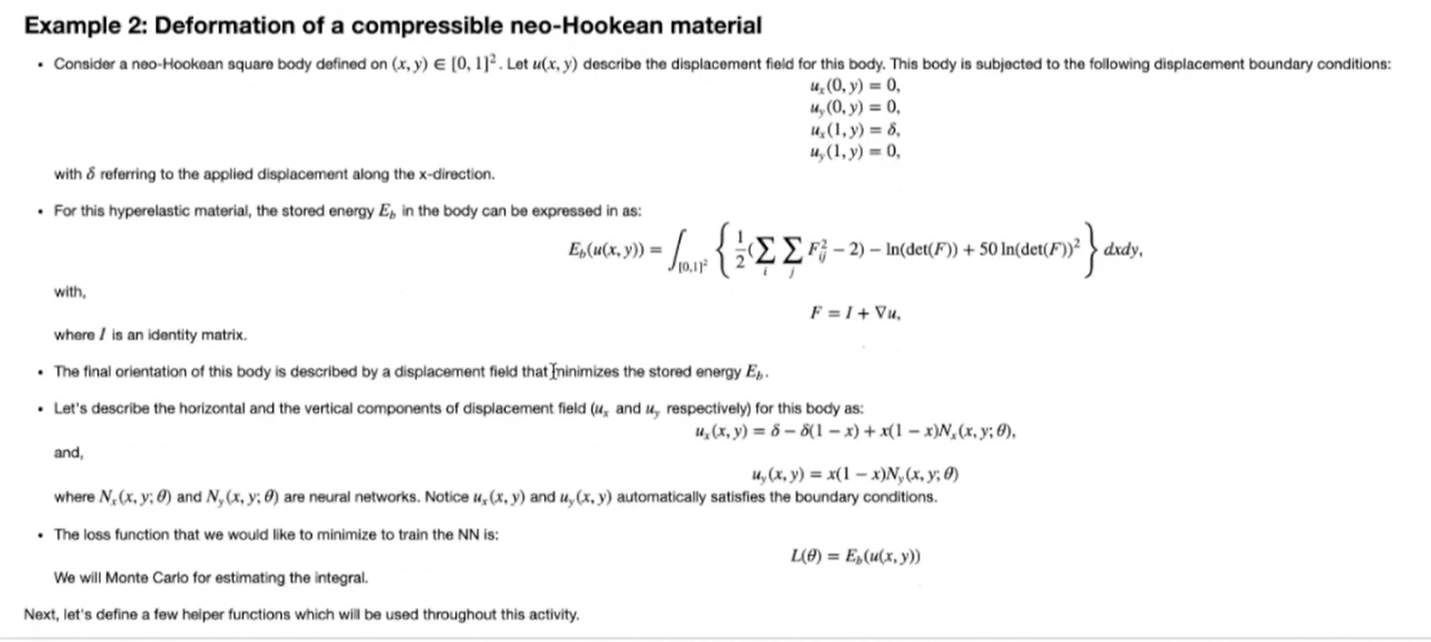

#Helper Functions

### Displacement Function

In [6]:
def u_r(x, delta, network1, network2, scale_network_out):

  u_x = delta[0] - delta[0]*(1. - x[:,0][:,None]) + x[:,0][:,None]*(1. - x[:,0][:,None])*network1(x)/scale_network_out
  u_y = x[:,0][:,None]*(1. - x[:,0][:,None])*network2(x)/scale_network_out
  u_r = torch.cat((u_x, u_y), dim=1)
  return u_r

## **Loss Function**

In [7]:
def loss(X, u_r):

  """
  This is our loss function that we want to minimize.
  -> X: inputs data. Should be of shape: (batch_size x 2)
  -> Displacement function (which requires only X as input)
  """

  X.required_grad = True
  # Finding the derivative of u WRT X for the each batch item and
  # storing it in u_r_x.

  u_r_x = torch.zeros(X.shape[0], X.shape[1], X.shape[1], device=device)
  for i in range(X.shape[0]):
     u_r_x[i,:,:] = torch.autograd.functional.jacobian(u_r, X[i][None,:], create_graph=True)[0,:,0,:]

    # Finding the energy corresponding to each batch item and
    # storing it in energy_tensor.

  energy_tensor = torch.zeros(X.shape[0], 1, device=device)
  for j in range(X.shape[0]):
      F = torch.eye(u_r_x[j].shape[0], device=device) + u_r_x[j]
      energy_tensor[j] = 0.5 * (torch.sum((F)**2) - 2.0) - torch.log((torch.det(F))) + 50.0 * torch.log((torch.det(F)))**2

  return torch.mean(energy_tensor)

## Training Loop

In [26]:
def train_MultiFieldFracture_seperate_net(net1, net2, right_edge_displacement, batch_size_X, max_iter, print_results_every, scale_network_out, lr=1e-3):
  """
  Trains given networks
  -> right_edge_displacement: corresponds to boundary condition (delta) on the right edge. Example: 0.5
  -> batch_size_X : how many X' do you want to use for each iteration. Example: 10
  -> print_results_every : how often do you want to display the results. Example: 100
  """

  print('\nStarting training loop with seperate networks for u_x and u_y... \n')
  print('Right Edge Displacement: %.3f'%right_edge_displacement, '\t\tbatch_size_X: %d'%batch_size_X, '\t\tmax_iter:%d\n'%max_iter)
  network1 = net1.to(device)
  network2 = net2.to(device)

  # Dirichlet boundary condition
  delta = torch.tensor([right_edge_displacement], device=device)

  # CRITICAL FIX: Optimize parameters of BOTH networks
  parameters = list(network1.parameters()) + list(network2.parameters())

  # Using Adam with a slightly higher default learning rate for faster convergence
  optimizer = torch.optim.Adam(parameters, lr=lr)

  start_time = perf_counter()
  loss_list = []
  elapsed_time = 0.0
  running_loss = 0.0

  for i in range(max_iter):
      X = torch.distributions.Uniform(0, 1).sample((batch_size_X, 2))
      X = X.to(device)

      optimizer.zero_grad()
      l = loss(X, partial(u_r, delta=delta, network1=network1, network2=network2, scale_network_out=scale_network_out))

      running_loss += l.item()
      l.backward()
      optimizer.step()

      if (i+1)%print_results_every == 0:
          current_time = perf_counter()
          elapsed_time = current_time - start_time
          avg_loss = running_loss/print_results_every
          print('[iter: %d]  elapsed: %d s  Loss: %.4f' % (i+1, elapsed_time, avg_loss))
          loss_list.append(avg_loss)
          running_loss = 0.0

  return loss_list, network1, network2

### ***Model Capacity***

In [9]:
def model_capacity(net):
  """
  Prints the number of parameters and the number of layres in the network
  -> Requires a neural network as input
  """

  number_of_learnable_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
  num_layers = len(list(net.parameters()))
  print('\n The number of layers in the model: %d' % num_layers)
  print("The number of learnable parameters in the model: %d\n" % number_of_learnable_params)

### ***Plots***

In [10]:
def plot_loss(loss, label):
    """
    -> loss: list containing the losses
    -> label: label for this loss
    """
    plt.plot(100*np.arange(len(loss)), loss, label='%s' %label)
    plt.xlabel('Iterations')
    plt.ylabel('Loss')
    plt.legend(loc='best')

def plot_displacement(network1, network2,
                      right_edge_displacement,
                      scale_network_out,
                      num_samples_X = 200, s= 4,
                      ):
  """
  Plots the horizontal and vertical components of displacements at given number of points.
  -> network1: first network
  -> network2: second network
  -> right_edge_displacement: corresponds to boundary condition (delta) on the right edge. Example: 0.5
  -> num_samples_X : no. of grid points
  -> s: Marker size
  """

  # Dirichlet Boundary Condition
  delta = torch.tensor(([right_edge_displacement, 0.0]))  # Contains the x and y coordinates of the displacement applied to the body

  for i in range(1):
      figure, ax = plt.subplots(1, 2, figsize=(20, 5))

      X_init = torch.linspace(0, 1, num_samples_X)
      xx, yy = torch.meshgrid(X_init, X_init)
      X_init = torch.cat((xx.reshape(-1)[..., None], yy.reshape(-1)[..., None]), axis=1 )

      displacement = u_r(X_init, delta, network1, network2, scale_network_out).detach().numpy()
      X_final_dual = X_init + displacement
      X_final_dual = X_final_dual.numpy()

      sc1 = ax[0].scatter(
        X_final_dual[:, 0],
        X_final_dual[:, 1],
        s=8,
        c=displacement[:, 0],
        cmap=plt.cm.get_cmap('copper')
      )
      plt.colorbar(sc1, ax=ax[0])
      ax[0].set_title('Horizontal Displacement ($u_x$)')

      sc2 = ax[1].scatter(
        X_final_dual[:, 0],
        X_final_dual[:, 1],
        s=8,
        c=displacement[:, 1],
        cmap=plt.cm.get_cmap('copper')
      )
      plt.colorbar(sc2, ax=ax[1])
      ax[1].set_title('Vertical Displacement ($u_y$)')

      plt.tight_layout()

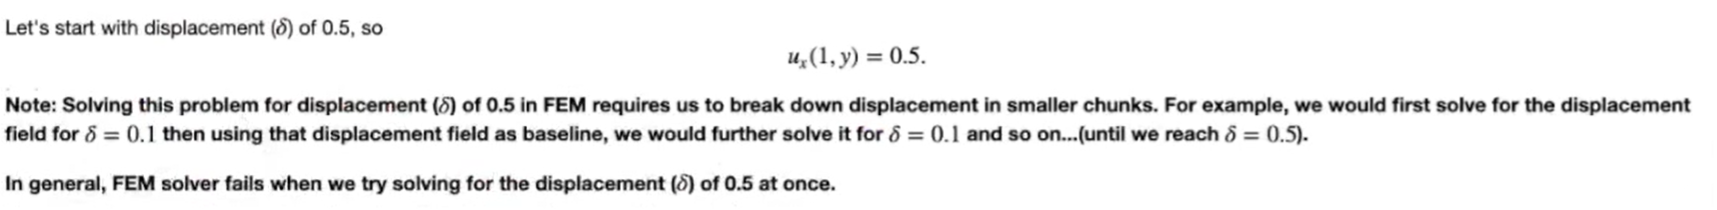

In [11]:
right_edge_displacement = 0.5
scale_network_out = 5

## **Part A: Simple fully connected Neural Network**

Let's begin with a simplest case where we have simple fully connected neural networks for both the horizontal displacement u^x and the vertical displacement u^y

**Define Model**

In [12]:
# Here is the network for the u_x
simple_net1 = nn.Sequential(nn.Linear(2, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 1)
)

# Here is the network for the u_y
simple_net2 = nn.Sequential(nn.Linear(2, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 50),
                     nn.Sigmoid(),
                     nn.Linear(50, 1)
)

# Redefine model_capacity here to ensure the fixed version is loaded in the active runtime
def model_capacity(net):
  number_of_learnable_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
  num_layers = len(list(net.parameters()))
  print('\n The number of layers in the model: %d' % num_layers)
  print("The number of learnable parameters in the model: %d\n" % number_of_learnable_params)

# Find the number of layers and model parameters in each network
model_capacity(simple_net1)
model_capacity(simple_net2)


 The number of layers in the model: 16
The number of learnable parameters in the model: 15501


 The number of layers in the model: 14
The number of learnable parameters in the model: 12951



/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/tmp/ipykernel_1648/3996857598.py:36: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  X_final_dual = X_init + displacement
/tmp/ipykernel_1648/3996857598.py:44: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('copper')
/tmp/ipykernel_1648/3996857598.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colorma

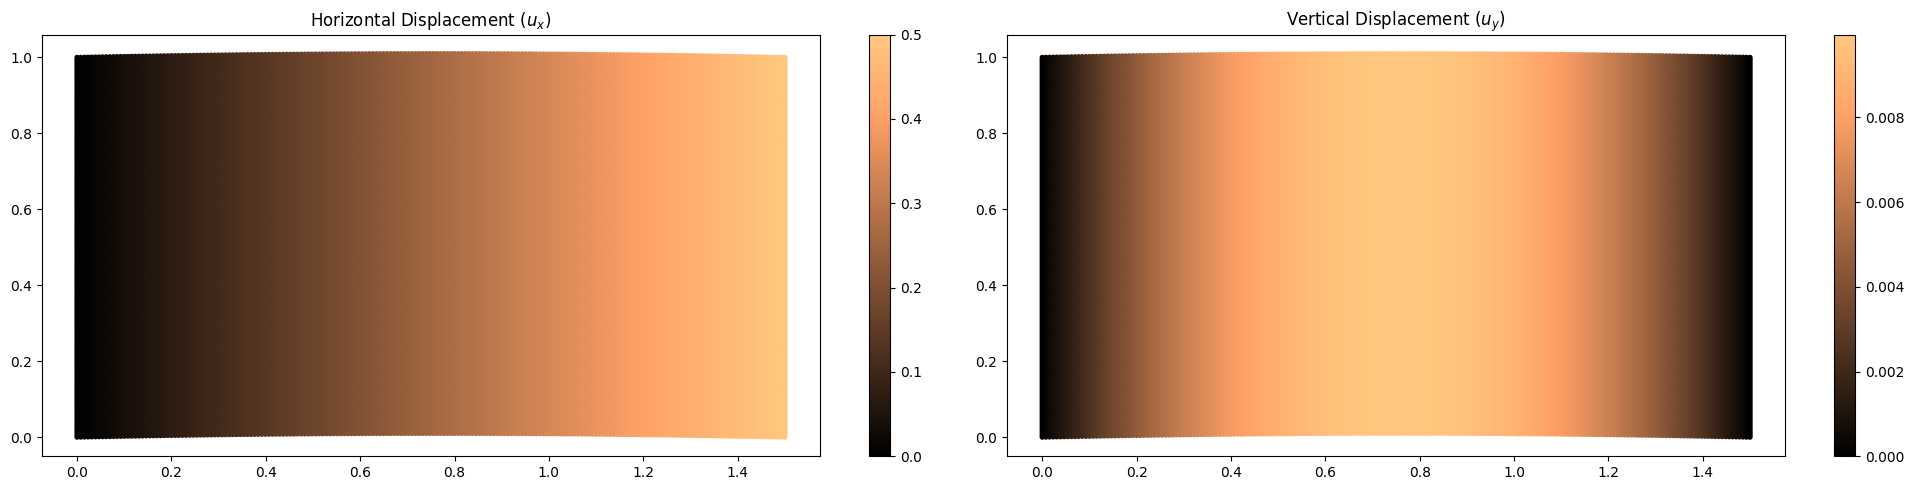

In [13]:
plot_displacement(simple_net1, simple_net2,
                  right_edge_displacement, scale_network_out)

In [27]:
# Re-initialize networks to reset their weights
simple_net1 = nn.Sequential(nn.Linear(2, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 1)).to(device)

simple_net2 = nn.Sequential(nn.Linear(2, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 50), nn.Sigmoid(),
                            nn.Linear(50, 1)).to(device)

# Run training with the parameter update fix and a learning rate of 1e-3 for 5000 iterations
loss_list_simple_net, simple_net1, simple_net2 = train_MultiFieldFracture_seperate_net(
    net1=simple_net1,
    net2=simple_net2,
    right_edge_displacement=right_edge_displacement,
    batch_size_X=15,
    max_iter=5000,
    print_results_every=100,
    scale_network_out=scale_network_out,
    lr=1e-3
)


Starting training loop with seperate networks for u_x and u_y... 

Right Edge Displacement: 0.500 		batch_size_X: 15 		max_iter:5000

[iter: 100]  elapsed: 12 s  Loss: 7.1059
[iter: 200]  elapsed: 24 s  Loss: 2.6258
[iter: 300]  elapsed: 38 s  Loss: 2.2898
[iter: 400]  elapsed: 50 s  Loss: 2.2353
[iter: 500]  elapsed: 63 s  Loss: 2.1171
[iter: 600]  elapsed: 76 s  Loss: 2.0541
[iter: 700]  elapsed: 89 s  Loss: 1.7016
[iter: 800]  elapsed: 102 s  Loss: 1.0677
[iter: 900]  elapsed: 114 s  Loss: 0.6991
[iter: 1000]  elapsed: 127 s  Loss: 0.5793
[iter: 1100]  elapsed: 141 s  Loss: 0.5260
[iter: 1200]  elapsed: 154 s  Loss: 0.4651
[iter: 1300]  elapsed: 167 s  Loss: 0.4656
[iter: 1400]  elapsed: 178 s  Loss: 0.4530
[iter: 1500]  elapsed: 190 s  Loss: 0.4637
[iter: 1600]  elapsed: 202 s  Loss: 0.4456
[iter: 1700]  elapsed: 216 s  Loss: 0.4648
[iter: 1800]  elapsed: 230 s  Loss: 0.4507
[iter: 1900]  elapsed: 241 s  Loss: 0.4595
[iter: 2000]  elapsed: 254 s  Loss: 0.4615
[iter: 2100]  elapsed

# Analyze Training Loss and Material Displacement

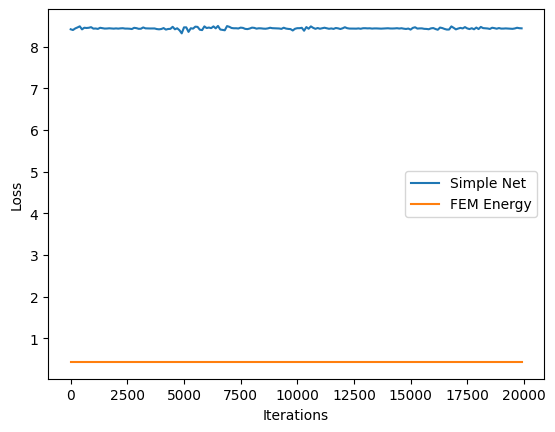

In [24]:
# Let's visualize the training loss
figure, ax = plt.subplots(dpi=100)
plot_loss(loss_list_simple_net, "Simple Net")

if right_edge_displacement==0.05:
    ax.plot(100*np.arange(len(loss_list_simple_net)), 0.006*np.ones(len(loss_list_simple_net)), label='FEM Energy')
elif right_edge_displacement==0.5:
    ax.plot(100*np.arange(len(loss_list_simple_net)), 0.43*np.ones(len(loss_list_simple_net)), label='FEM Energy')
plt.legend(loc='best');

### Corrected Loss Visualization
Let's plot the loss with the corrected X-axis iteration scaling (since `print_results_every` was set to `10`, we multiply by 10 instead of 100).

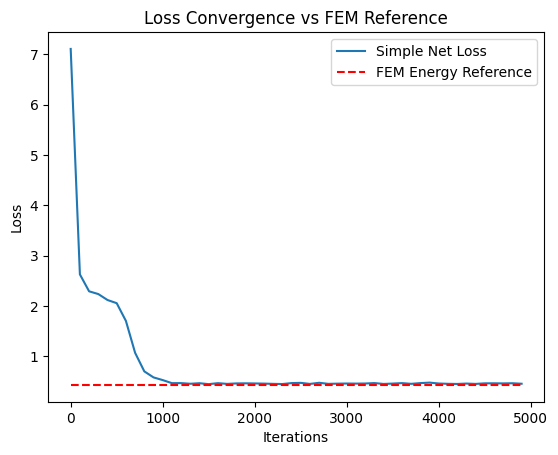

In [28]:
# Plot the newly trained loss to watch it converge down toward the FEM Energy line
figure, ax = plt.subplots(dpi=100)

# Since print_results_every = 100, we multiply the x-axis by 100
iterations = 100 * np.arange(len(loss_list_simple_net))
plt.plot(iterations, loss_list_simple_net, label="Simple Net Loss")

if right_edge_displacement == 0.05:
    ax.plot(iterations, 0.006 * np.ones(len(loss_list_simple_net)), 'r--', label='FEM Energy Reference')
elif right_edge_displacement == 0.5:
    ax.plot(iterations, 0.43 * np.ones(len(loss_list_simple_net)), 'r--', label='FEM Energy Reference')

plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend(loc='best')
plt.title('Loss Convergence vs FEM Reference')
plt.show()

/tmp/ipykernel_1648/3996857598.py:36: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  X_final_dual = X_init + displacement
/tmp/ipykernel_1648/3996857598.py:44: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('copper')
/tmp/ipykernel_1648/3996857598.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('copper')


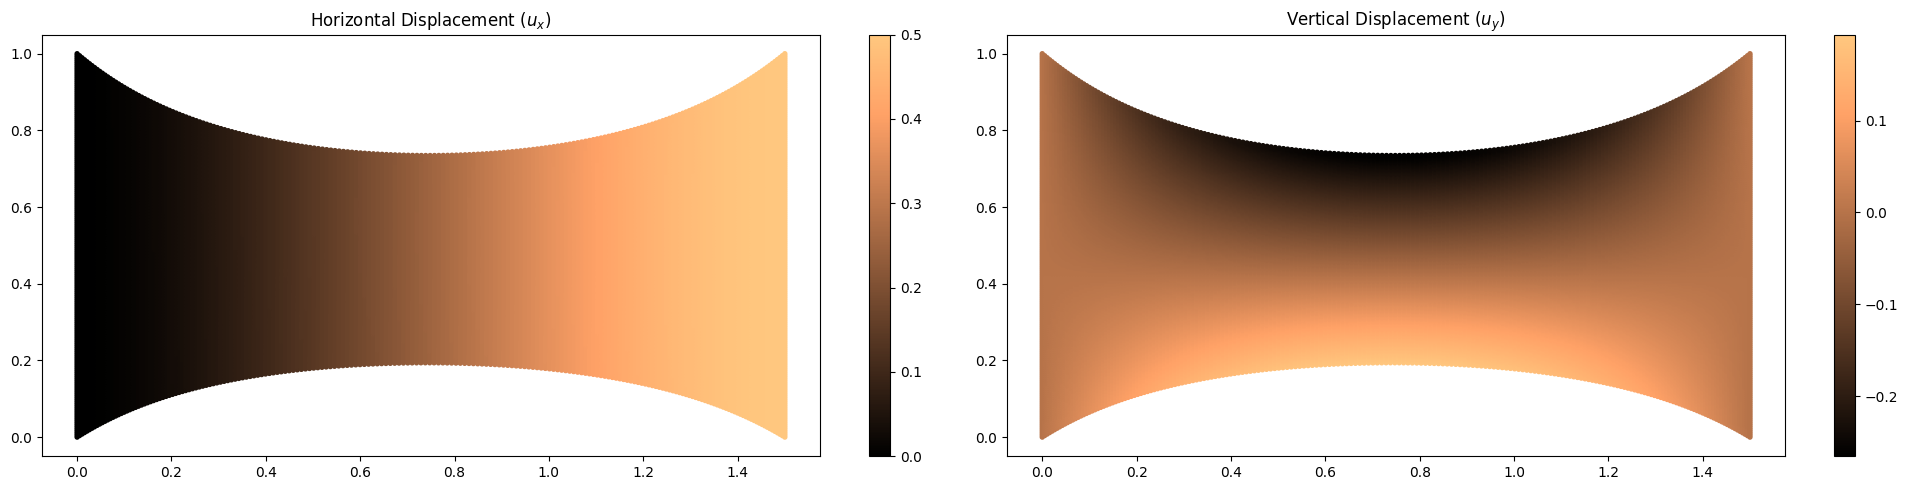

In [29]:
plot_displacement(simple_net1, simple_net2, right_edge_displacement, scale_network_out)